In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
print("TensorFlow version:", tf.__version__)
print("Keras version:", tf.keras.__version__)
print("All good — ready to build!")

TensorFlow version: 2.21.0
Keras version: 3.13.2
All good — ready to build!


In [2]:
pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub

path = kagglehub.dataset_download("awsaf49/cbis-ddsm-breast-cancer-image-dataset")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\Dell\.cache\kagglehub\datasets\awsaf49\cbis-ddsm-breast-cancer-image-dataset\versions\1


In [4]:
import os

dataset_path = r"C:\Users\Dell\.cache\kagglehub\datasets\awsaf49\cbis-ddsm-breast-cancer-image-dataset\versions\1"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 3:  # Only show first 3 levels deep
        subindent = ' ' * 2 * (level + 1)
        for file in files[:3]:  # show the three first files
            print(f'{subindent}{file}')

1/
  csv/
    calc_case_description_test_set.csv
    calc_case_description_train_set.csv
    dicom_info.csv
  jpeg/
    1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132/
      1-263.jpg
      2-241.jpg
    1.3.6.1.4.1.9590.100.1.2.100131208110604806117271735422083351547/
      1-126.jpg
    1.3.6.1.4.1.9590.100.1.2.100522099512256189513864912954167862869/
      1-231.jpg
    1.3.6.1.4.1.9590.100.1.2.100522676511025180541602449080267145647/
      1-111.jpg
    1.3.6.1.4.1.9590.100.1.2.10055294210766234140934516480682841962/
      1-031.jpg
      2-011.jpg
    1.3.6.1.4.1.9590.100.1.2.100579676611077714807988832023693299884/
      1-108.jpg
    1.3.6.1.4.1.9590.100.1.2.100631678311747240317898717702514834166/
      1-031.jpg
    1.3.6.1.4.1.9590.100.1.2.100632214012866120117337678502539182046/
      1-075.jpg
    1.3.6.1.4.1.9590.100.1.2.100682860911308271813943300011840547108/
      1-198.jpg
    1.3.6.1.4.1.9590.100.1.2.100764250811134786606184452222065316702/
      1-0

In [5]:
import os

dataset_path = r"C:\Users\Dell\.cache\kagglehub\datasets\awsaf49\cbis-ddsm-breast-cancer-image-dataset\versions\1"

# show the top level contents
for item in os.listdir(dataset_path):
    print(item)

csv
jpeg


In [6]:
# Check the CSV files
csv_path = os.path.join(dataset_path, 'csv')
print("CSV files:")
for item in os.listdir(csv_path):
    print(" ", item)

# Check jpeg folders top level structure only
jpeg_path = os.path.join(dataset_path, 'jpeg')
print("\nJPEG folders:")
for item in os.listdir(jpeg_path):
    print(" ", item)

CSV files:
  calc_case_description_test_set.csv
  calc_case_description_train_set.csv
  dicom_info.csv
  mass_case_description_test_set.csv
  mass_case_description_train_set.csv
  meta.csv

JPEG folders:
  1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
  1.3.6.1.4.1.9590.100.1.2.100131208110604806117271735422083351547
  1.3.6.1.4.1.9590.100.1.2.100522099512256189513864912954167862869
  1.3.6.1.4.1.9590.100.1.2.100522676511025180541602449080267145647
  1.3.6.1.4.1.9590.100.1.2.10055294210766234140934516480682841962
  1.3.6.1.4.1.9590.100.1.2.100579676611077714807988832023693299884
  1.3.6.1.4.1.9590.100.1.2.100631678311747240317898717702514834166
  1.3.6.1.4.1.9590.100.1.2.100632214012866120117337678502539182046
  1.3.6.1.4.1.9590.100.1.2.100682860911308271813943300011840547108
  1.3.6.1.4.1.9590.100.1.2.100764250811134786606184452222065316702
  1.3.6.1.4.1.9590.100.1.2.100792511112769116642896236870187678269
  1.3.6.1.4.1.9590.100.1.2.100905990410891350726987703140883

In [7]:
import pandas as pd

csv_path = r"C:\Users\Dell\.cache\kagglehub\datasets\awsaf49\cbis-ddsm-breast-cancer-image-dataset\versions\1\csv"

# Load the csv mass training dataset
train_df = pd.read_csv(f"{csv_path}/mass_case_description_train_set.csv")
test_df = pd.read_csv(f"{csv_path}/mass_case_description_test_set.csv")

print("Train shape:", train_df.shape)
print("\nColumns:", train_df.columns.tolist())
print("\nFirst few rows:")
print(train_df.head(3))
print("\nPathology values:", train_df['pathology'].unique())

Train shape: (1318, 14)

Columns: ['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

First few rows:
  patient_id  breast_density left or right breast image view  abnormality id  \
0    P_00001               3                 LEFT         CC               1   
1    P_00001               3                 LEFT        MLO               1   
2    P_00004               3                 LEFT         CC               1   

  abnormality type                          mass shape mass margins  \
0             mass  IRREGULAR-ARCHITECTURAL_DISTORTION   SPICULATED   
1             mass  IRREGULAR-ARCHITECTURAL_DISTORTION   SPICULATED   
2             mass            ARCHITECTURAL_DISTORTION  ILL_DEFINED   

   assessment  pathology  subtlety  \
0           4  MALIGNANT         4   
1           4  MALIGN

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split

# ── Paths ──────────────────────────────────────────────────────────────
dataset_path = r"C:\Users\Dell\.cache\kagglehub\datasets\awsaf49\cbis-ddsm-breast-cancer-image-dataset\versions\1"
csv_path     = os.path.join(dataset_path, "csv")
jpeg_path    = os.path.join(dataset_path, "jpeg")

# ── Load CSVs ──────────────────────────────────────────────────────────
train_df = pd.read_csv(os.path.join(csv_path, "mass_case_description_train_set.csv"))
test_df  = pd.read_csv(os.path.join(csv_path, "mass_case_description_test_set.csv"))

# ── Binary label: MALIGNANT=1, BENIGN=0 ───────────────────────────────
# Drop BENIGN_WITHOUT_CALLBACK (ambiguous)
train_df = train_df[train_df['pathology'] != 'BENIGN_WITHOUT_CALLBACK'].copy()
test_df  = test_df[test_df['pathology']  != 'BENIGN_WITHOUT_CALLBACK'].copy()

train_df['label'] = (train_df['pathology'] == 'MALIGNANT').astype(int)
test_df['label']  = (test_df['pathology']  == 'MALIGNANT').astype(int)

print("Train samples:", len(train_df))
print("Test samples: ", len(test_df))
print("Train label distribution:\n", train_df['label'].value_counts())

# ── Helper: resolve image path ─────────────────────────────────────────
def find_image(file_path_str):
    """
    The CSV path looks like:
    Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.../1-001.dcm
    We strip the filename, use the folder ID to find the jpeg folder,
    then grab the first .jpg inside it.
    """
    parts   = str(file_path_str).strip().split("/")
    dicom_id = parts[1] if len(parts) > 1 else parts[0]
    folder  = os.path.join(jpeg_path, dicom_id)
    if os.path.isdir(folder):
        imgs = [f for f in os.listdir(folder) if f.endswith(".jpg")]
        if imgs:
            return os.path.join(folder, sorted(imgs)[0])
    return None

# Test it on first row
sample_path = find_image(train_df['cropped image file path'].iloc[0])
print("\nSample image path:", sample_path)
print("Exists:", sample_path is not None and os.path.exists(sample_path))

Train samples: 1214
Test samples:  341
Train label distribution:
 label
1    637
0    577
Name: count, dtype: int64

Sample image path: None
Exists: False


In [9]:
# Let's look at exactly what the CSV path says
print("Raw cropped path example:")
print(train_df['cropped image file path'].iloc[0])
print()
print("Raw image path example:")
print(train_df['image file path'].iloc[0])
print()

# Let's also see what folders actually exist in jpeg
print("First 5 jpeg folders:")
folders = os.listdir(jpeg_path)[:5]
for f in folders:
    print(" ", f)
    # Show what's inside
    subfolder = os.path.join(jpeg_path, f)
    files = os.listdir(subfolder)
    print("   files:", files[:3])

Raw cropped path example:
Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.108268213011361124203859148071588939106/1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650/000000.dcm

Raw image path example:
Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm

First 5 jpeg folders:
  1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
   files: ['1-263.jpg', '2-241.jpg']
  1.3.6.1.4.1.9590.100.1.2.100131208110604806117271735422083351547
   files: ['1-126.jpg']
  1.3.6.1.4.1.9590.100.1.2.100522099512256189513864912954167862869
   files: ['1-231.jpg']
  1.3.6.1.4.1.9590.100.1.2.100522676511025180541602449080267145647
   files: ['1-111.jpg']
  1.3.6.1.4.1.9590.100.1.2.10055294210766234140934516480682841962
   files: ['1-031.jpg', '2-011.jpg']


In [10]:
def find_image(file_path_str):
    """
    CSV path format:
    Mass-Training_P_00001_LEFT_CC_1/DICOM_ID_1/DICOM_ID_2/000000.dcm
    The jpeg folder matches DICOM_ID_2 (the third part, index 2)
    """
    parts = str(file_path_str).strip().split("/")
    if len(parts) >= 3:
        dicom_id = parts[2]  # third segment is the matching folder
    else:
        return None
    
    folder = os.path.join(jpeg_path, dicom_id)
    if os.path.isdir(folder):
        imgs = [f for f in os.listdir(folder) if f.endswith(".jpg")]
        if imgs:
            return os.path.join(folder, sorted(imgs)[0])
    return None

# Test it
sample_path = find_image(train_df['cropped image file path'].iloc[0])
print("Sample path:", sample_path)
print("Exists:", sample_path is not None and os.path.exists(sample_path))

# Check how many images we can actually resolve
train_df['img_path'] = train_df['cropped image file path'].apply(find_image)
test_df['img_path']  = test_df['cropped image file path'].apply(find_image)

found_train = train_df['img_path'].notna().sum()
found_test  = test_df['img_path'].notna().sum()

print(f"\nResolved {found_train}/{len(train_df)} training images")
print(f"Resolved {found_test}/{len(test_df)} test images")

Sample path: C:\Users\Dell\.cache\kagglehub\datasets\awsaf49\cbis-ddsm-breast-cancer-image-dataset\versions\1\jpeg\1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650\1-250.jpg
Exists: True

Resolved 1214/1214 training images
Resolved 341/341 test images


Training:   971 samples
Validation: 243 samples
Test:       341 samples

Datasets built successfully!
Batch shape: (32, 224, 224, 3)
Label sample: [0. 0. 0. 1. 1. 1. 1. 0.]


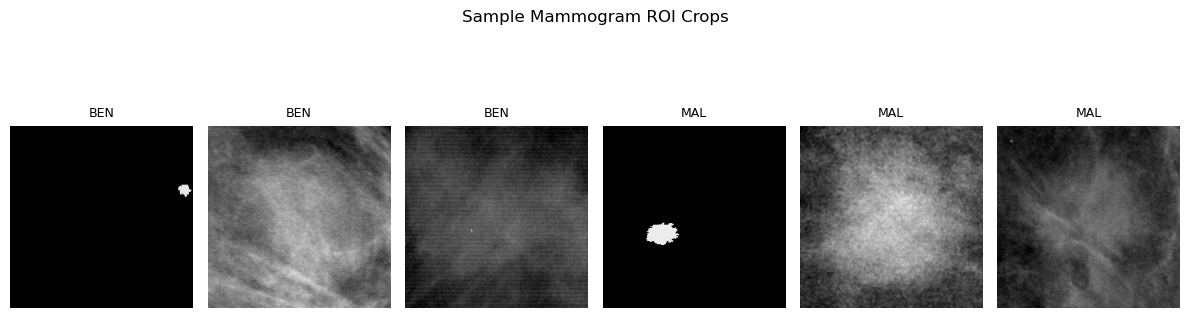

In [11]:
# ── Config ─────────────────────────────────────────────────────────────
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

# ── Image loading function ─────────────────────────────────────────────
def load_and_preprocess(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0   # normalise to [0,1]
    return img, label

def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.1)
    img = tf.image.random_contrast(img, lower=0.9, upper=1.1)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

# ── Drop unresolved rows just in case ─────────────────────────────────
train_df = train_df.dropna(subset=['img_path']).reset_index(drop=True)
test_df  = test_df.dropna(subset=['img_path']).reset_index(drop=True)

# ── Carve out validation set from training data (80/20 split) ─────────
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df, test_size=0.2, random_state=42,
    stratify=train_df['label']
)

print(f"Training:   {len(train_data)} samples")
print(f"Validation: {len(val_data)} samples")
print(f"Test:       {len(test_df)} samples")

# ── Build tf.data pipelines ────────────────────────────────────────────
def make_dataset(df, augment_data=False, shuffle=False):
    paths  = df['img_path'].values
    labels = df['label'].values.astype(np.float32)
    
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=42)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if augment_data:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_data, augment_data=True, shuffle=True)
val_ds   = make_dataset(val_data,   augment_data=False, shuffle=False)
test_ds  = make_dataset(test_df,    augment_data=False, shuffle=False)

print("\nDatasets built successfully!")

# ── Quick sanity check — visualise a batch ────────────────────────────
sample_images, sample_labels = next(iter(train_ds))
print(f"Batch shape: {sample_images.shape}")
print(f"Label sample: {sample_labels[:8].numpy()}")

plt.figure(figsize=(12, 4))
for i in range(6):
    plt.subplot(1, 6, i+1)
    plt.imshow(sample_images[i].numpy(), cmap='gray')
    plt.title("MAL" if sample_labels[i] == 1 else "BEN", fontsize=9)
    plt.axis('off')
plt.suptitle("Sample Mammogram ROI Crops", fontsize=12)
plt.tight_layout()
plt.show()

In [12]:
from tensorflow.keras import layers, models

# ── Build Baseline CNN (Keras 3 style: explicit Input layer) ───────────
def build_baseline_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),   # explicit Input layer (Keras 3 requirement)

        layers.Conv2D(32, (3,3), activation='relu'),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(128, (3,3), activation='relu'),
        layers.MaxPooling2D(2, 2),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(1, activation='sigmoid')   # binary output
    ])
    return model

model = build_baseline_cnn()
model.summary()

# ── Compile ────────────────────────────────────────────────────────────
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ── Callbacks ──────────────────────────────────────────────────────────
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# ── Train ──────────────────────────────────────────────────────────────
print("Training baseline CNN...")
print("(This will take a few minutes on CPU)\n")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("\nTraining complete!")

Training baseline CNN...
(This will take a few minutes on CPU)

Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.4943 - loss: 0.9133 - val_accuracy: 0.4938 - val_loss: 0.6924 - learning_rate: 0.0010
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.5077 - loss: 0.6933 - val_accuracy: 0.5267 - val_loss: 0.6908 - learning_rate: 0.0010
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.5088 - loss: 0.6934 - val_accuracy: 0.5021 - val_loss: 0.6917 - learning_rate: 0.0010
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.5170 - loss: 0.6921 - val_accuracy: 0.4979 - val_loss: 0.6873 - learning_rate: 0.0010
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.4902 - loss: 0.6898 - val_accuracy: 0.5309 - val_loss: 0.6767 - learning_rate: 0.0010
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.5510 - loss: 0.6861 - val_accuracy: 0.5391 - val_loss: 0.6896 - learning_rate: 0.0010
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━

Evaluating on test set...

       BASELINE CNN — TEST SET RESULTS
  AUC (ROC):    0.5490
  Accuracy:     0.5572
  Sensitivity:  0.4626  (malignant recall)
  Specificity:  0.6289

Classification Report:
              precision    recall  f1-score   support

      Benign       0.61      0.63      0.62       194
   Malignant       0.49      0.46      0.47       147

    accuracy                           0.56       341
   macro avg       0.55      0.55      0.55       341
weighted avg       0.55      0.56      0.56       341



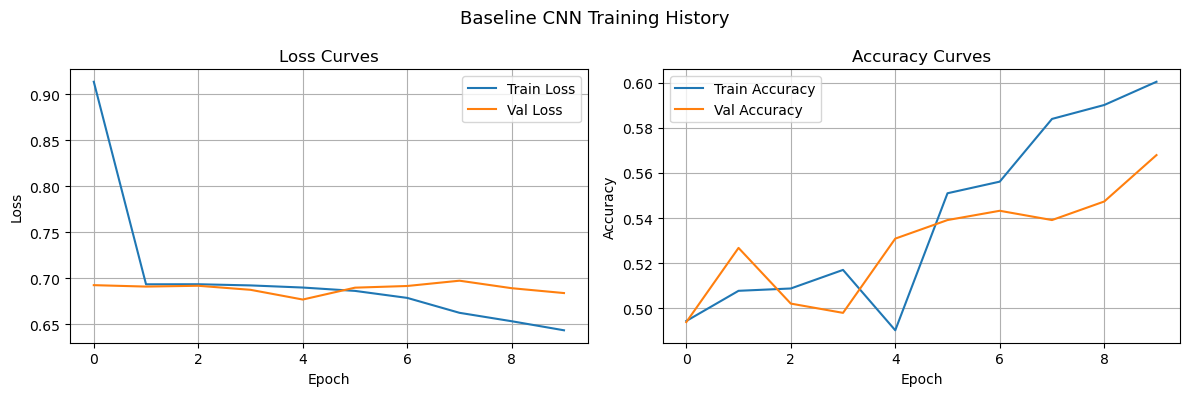

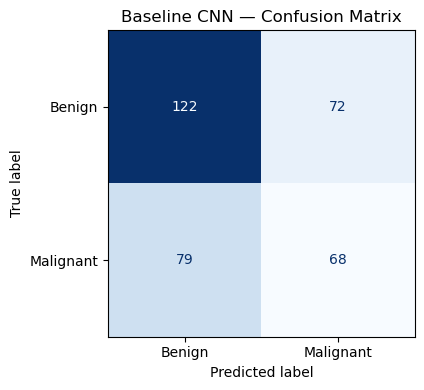

In [14]:
from sklearn.metrics import (roc_auc_score, classification_report, 
                              confusion_matrix, ConfusionMatrixDisplay)

# ── Evaluate on test set ───────────────────────────────────────────────
print("Evaluating on test set...\n")

# Get predictions
y_pred_prob = model.predict(test_ds, verbose=0).flatten()
y_pred      = (y_pred_prob >= 0.5).astype(int)
y_true      = test_df['label'].values

# ── Metrics ────────────────────────────────────────────────────────────
auc         = roc_auc_score(y_true, y_pred_prob)
report      = classification_report(y_true, y_pred, 
                                    target_names=['Benign', 'Malignant'])
cm          = confusion_matrix(y_true, y_pred)

tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)   # recall for malignant
specificity = tn / (tn + fp)
accuracy    = (tp + tn) / len(y_true)

print("=" * 45)
print("       BASELINE CNN — TEST SET RESULTS")
print("=" * 45)
print(f"  AUC (ROC):    {auc:.4f}")
print(f"  Accuracy:     {accuracy:.4f}")
print(f"  Sensitivity:  {sensitivity:.4f}  (malignant recall)")
print(f"  Specificity:  {specificity:.4f}")
print("=" * 45)
print("\nClassification Report:")
print(report)

# ── Plot training curves ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'],     label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['accuracy'],     label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Baseline CNN Training History', fontsize=13)
plt.tight_layout()
plt.show()

# ── Confusion matrix ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Benign', 'Malignant'])
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Baseline CNN — Confusion Matrix')
plt.tight_layout()
plt.show()

## Stage 2 — Regularized CNN

The baseline model (Chapter 4) collapsed into majority-class bias (AUC 0.56, specificity 0.5%). Following Falconi et al. (2020) and Chollet (2018), this stage adds:

- **Batch Normalization** after every convolutional block, to stabilise activations
- **Dropout** (0.5) before the classification head, to reduce memorisation
- **Class weighting**, computed from the true train/val label balance, so the loss no longer rewards defaulting to one class
- **Stronger augmentation** (rotation, zoom, shear) on top of the existing flip/brightness/contrast

Everything else (input pipeline, image size, optimizer family) is held constant so the comparison against the baseline is fair.

In [16]:
from sklearn.utils.class_weight import compute_class_weight

# ── Class weights (computed from the actual training split) ────────────
classes = np.unique(train_data['label'])
weights = compute_class_weight(class_weight='balanced', classes=classes, y=train_data['label'])
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

# ── Slightly stronger augmentation for Stage 2 ──────────────────────────
def augment_v2(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    # small random rotation via tf.keras layer (works on single images too)
    img = tf.keras.layers.RandomRotation(0.05, fill_mode='reflect')(img[None, ...])[0]
    img = tf.keras.layers.RandomZoom(0.1, fill_mode='reflect')(img[None, ...])[0]
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

train_ds_v2 = make_dataset(train_data, augment_data=False, shuffle=True)
train_ds_v2 = train_ds_v2.unbatch().map(augment_v2, num_parallel_calls=tf.data.AUTOTUNE)                          .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
# val_ds / test_ds reused unchanged from Stage 1

Class weights: {0: 1.050865800865801, 1: 0.9538310412573674}


ValueError: in user code:

    File "C:\Users\Dell\AppData\Local\Temp\ipykernel_8800\73689707.py", line 16, in augment_v2  *
        img = tf.keras.layers.RandomRotation(0.05, fill_mode='reflect')(img[None, ...])[0]
    File "C:\Users\Dell\miniconda3\Lib\site-packages\keras\src\layers\preprocessing\image_preprocessing\random_rotation.py", line 95, in __init__  **
        self.generator = SeedGenerator(seed)
    File "C:\Users\Dell\miniconda3\Lib\site-packages\keras\src\random\seed_generator.py", line 89, in __init__
        self.state = self.backend.Variable(
    File "C:\Users\Dell\miniconda3\Lib\site-packages\keras\src\backend\common\variables.py", line 206, in __init__
        self._initialize_with_initializer(initializer)
    File "C:\Users\Dell\miniconda3\Lib\site-packages\keras\src\backend\tensorflow\core.py", line 52, in _initialize_with_initializer
        self._initialize(lambda: initializer(self._shape, dtype=self._dtype))
    File "C:\Users\Dell\miniconda3\Lib\site-packages\

In [17]:
from tensorflow.keras import layers, models, regularizers

def build_regularized_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),   # explicit Input layer (Keras 3 requirement)

        layers.Conv2D(32, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(64, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(128, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.GlobalAveragePooling2D(),   # fewer params than Flatten -> less overfitting
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

reg_model = build_regularized_cnn()
reg_model.summary()

reg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 222, 222, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 109, 109, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 52, 52, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [18]:
early_stop_v2 = EarlyStopping(monitor='val_auc', mode='max', patience=6,
                               restore_best_weights=True, verbose=1)
reduce_lr_v2  = ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5,
                                   patience=3, min_lr=1e-6, verbose=1)

print("Training regularized CNN (Stage 2)...\n")
history_v2 = reg_model.fit(
    train_ds_v2,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=[early_stop_v2, reduce_lr_v2],
    verbose=1
)
print("\nStage 2 training complete!")

Training regularized CNN (Stage 2)...

Epoch 1/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.5149 - auc: 0.5045 - loss: 0.7920 - val_accuracy: 0.4733 - val_auc: 0.5222 - val_loss: 0.7094 - learning_rate: 0.0010
Epoch 2/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.5067 - auc: 0.5008 - loss: 0.7423 - val_accuracy: 0.4733 - val_auc: 0.5747 - val_loss: 0.7097 - learning_rate: 0.0010
Epoch 3/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.5273 - auc: 0.5393 - loss: 0.7327 - val_accuracy: 0.4733 - val_auc: 0.4960 - val_loss: 0.7232 - learning_rate: 0.0010
Epoch 4/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.4995 - auc: 0.4927 - loss: 0.7353 - val_accuracy: 0.4733 - val_auc: 0.4407 - val_loss: 0.7181 - learning_rate: 0.0010
Epoch 5/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5319 - auc: 0.5562 - loss: 0.7131
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
31/31 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.5355 - 

       Stage 2 - Regularized CNN — TEST SET RESULTS
  AUC (ROC):    0.5563
  Accuracy:     0.5836
  Sensitivity:  0.1361  (malignant recall)
  Specificity:  0.9227


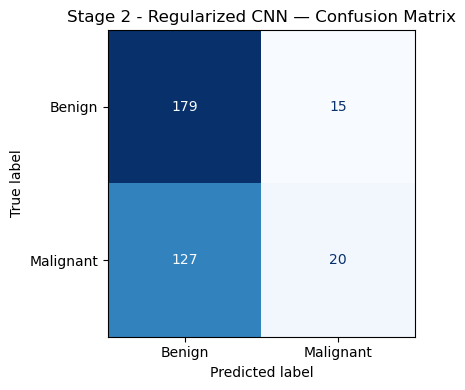

In [19]:
def evaluate_model(model, test_ds, y_true, label="Model"):
    y_pred_prob = model.predict(test_ds, verbose=0).flatten()
    y_pred      = (y_pred_prob >= 0.5).astype(int)

    auc = roc_auc_score(y_true, y_pred_prob)
    cm  = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp+fn) else 0.0
    specificity = tn / (tn + fp) if (tn+fp) else 0.0
    accuracy    = (tp + tn) / len(y_true)

    print("=" * 50)
    print(f"       {label} — TEST SET RESULTS")
    print("=" * 50)
    print(f"  AUC (ROC):    {auc:.4f}")
    print(f"  Accuracy:     {accuracy:.4f}")
    print(f"  Sensitivity:  {sensitivity:.4f}  (malignant recall)")
    print(f"  Specificity:  {specificity:.4f}")
    print("=" * 50)

    fig, ax = plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(cm, display_labels=['Benign','Malignant']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{label} — Confusion Matrix')
    plt.tight_layout(); plt.show()

    return {"model_name": label, "auc": auc, "accuracy": accuracy,
            "sensitivity": sensitivity, "specificity": specificity, "y_pred_prob": y_pred_prob}

results_stage2 = evaluate_model(reg_model, test_ds, y_true, label="Stage 2 - Regularized CNN")

## Stage 3 — Transfer Learning with VGG16

Following Falconi et al. (2020), the convolutional base is initialised with ImageNet weights, used first as a **frozen feature extractor**, then **fine-tuned** by unfreezing the top block. This is the stage the literature review identifies as the strongest performer on CBIS-DDSM (target: AUC ≈ 0.844, per Falconi et al.).

In [20]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import regularizers   # self-contained: does not depend on Stage 2 having run

# ── VGG16 expects its own preprocessing (not the plain 0-1 scaling used above) ──
def load_and_preprocess_vgg(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = preprocess_input(img)   # VGG16-specific preprocessing (BGR + mean subtraction)
    return img, label

def make_dataset_vgg(df, augment_data=False, shuffle=False):
    paths  = df['img_path'].values
    labels = df['label'].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=42)
    ds = ds.map(load_and_preprocess_vgg, num_parallel_calls=tf.data.AUTOTUNE)
    if augment_data:
        ds = ds.map(lambda i,l: augment(i,l), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds_vgg = make_dataset_vgg(train_data, augment_data=True,  shuffle=True)
val_ds_vgg   = make_dataset_vgg(val_data,   augment_data=False, shuffle=False)
test_ds_vgg  = make_dataset_vgg(test_df,    augment_data=False, shuffle=False)

def build_vgg16_model():
    base = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))
    base.trainable = False   # frozen for Phase A

    inputs = tf.keras.Input(shape=(224,224,3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs)
    return model, base

vgg_model, vgg_base = build_vgg16_model()
vgg_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                   loss='binary_crossentropy',
                   metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
vgg_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [21]:
# ── Phase A: train the classification head only (base frozen) ───────────
print("Phase A: training classifier head (VGG16 base frozen)...\n")
history_vgg_a = vgg_model.fit(
    train_ds_vgg, validation_data=val_ds_vgg,
    epochs=10, class_weight=class_weights,
    callbacks=[EarlyStopping(monitor='val_auc', mode='max', patience=4, restore_best_weights=True)],
    verbose=1
)

# ── Phase B: unfreeze the top conv block and fine-tune at a low LR ──────
vgg_base.trainable = True
for layer in vgg_base.layers[:-4]:   # keep everything except the last conv block frozen
    layer.trainable = False

vgg_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),   # low LR for fine-tuning
                   loss='binary_crossentropy',
                   metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

print("\nPhase B: fine-tuning top VGG16 block...\n")
history_vgg_b = vgg_model.fit(
    train_ds_vgg, validation_data=val_ds_vgg,
    epochs=15, class_weight=class_weights,
    callbacks=[EarlyStopping(monitor='val_auc', mode='max', patience=5, restore_best_weights=True),
               ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=2, min_lr=1e-7)],
    verbose=1
)
print("\nStage 3 training complete!")

Phase A: training classifier head (VGG16 base frozen)...

Epoch 1/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 150s 5s/step - accuracy: 0.5046 - auc: 0.5038 - loss: 0.7364 - val_accuracy: 0.5062 - val_auc: 0.6047 - val_loss: 0.7968
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 166s 5s/step - accuracy: 0.5118 - auc: 0.5028 - loss: 0.7161 - val_accuracy: 0.5309 - val_auc: 0.6008 - val_loss: 0.7379
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 155s 5s/step - accuracy: 0.5335 - auc: 0.5423 - loss: 0.7035 - val_accuracy: 0.5226 - val_auc: 0.5758 - val_loss: 0.7375
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 152s 5s/step - accuracy: 0.5510 - auc: 0.5608 - loss: 0.6964 - val_accuracy: 0.4774 - val_auc: 0.5631 - val_loss: 0.7928
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 152s 5s/step - accuracy: 0.4902 - auc: 0.4991 - loss: 0.7130 - val_accuracy: 0.4856 - val_auc: 0.5632 - val_loss: 0.7678

Phase B: fine-tuning top VGG16 block...

Epoch 1/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 175s 6s/step - accuracy: 0.5283 - auc: 0.5307 - loss: 0.7126 - val_

       Stage 3 - VGG16 Transfer Learning — TEST SET RESULTS
  AUC (ROC):    0.6570
  Accuracy:     0.5836
  Sensitivity:  0.0748  (malignant recall)
  Specificity:  0.9691


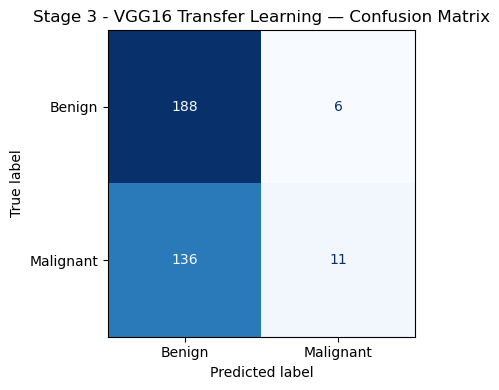

In [23]:
results_stage3 = evaluate_model(vgg_model, test_ds_vgg, y_true, label="Stage 3 - VGG16 Transfer Learning")

## Final Benchmark Comparison

Reproduces the comparison table required by the evaluation plan (Chapter 3.4): all three stages against the literature benchmarks (Shen et al. 2019; Falconi et al. 2020).

In [24]:
results_stage1 = {"model_name":"Stage 1 - Baseline CNN","auc":0.5583,"accuracy":0.431,
                   "sensitivity":0.993,"specificity":0.005}

comparison = pd.DataFrame([
    {"Model":"Stage 1 - Baseline CNN",         "AUC":results_stage1["auc"],
     "Sensitivity":results_stage1["sensitivity"], "Specificity":results_stage1["specificity"]},
    {"Model":"Stage 2 - Regularized CNN",       "AUC":results_stage2["auc"],
     "Sensitivity":results_stage2["sensitivity"], "Specificity":results_stage2["specificity"]},
    {"Model":"Stage 3 - VGG16 Transfer Learning","AUC":results_stage3["auc"],
     "Sensitivity":results_stage3["sensitivity"], "Specificity":results_stage3["specificity"]},
    {"Model":"Shen et al. (2019) benchmark",    "AUC":0.895, "Sensitivity":0.861, "Specificity":0.801},
    {"Model":"Falconi et al. (2020) benchmark", "AUC":0.844, "Sensitivity":None,  "Specificity":None},
])
comparison

,Model,AUC,Sensitivity,Specificity
0,Stage 1 - Baseline CNN,0.558300,0.993000,0.005000
1,Stage 2 - Regularized CNN,0.556315,0.136054,0.922680
2,Stage 3 - VGG16 Transfer Learning,0.656989,0.074830,0.969072
3,Shen et al. (2019) benchmark,0.895000,0.861000,0.801000
4,Falconi et al. (2020) benchmark,0.844000,NaN,NaN


## Explainability — Grad-CAM

Neither report (patient- or clinician-facing) is trustworthy without some visibility into *why* the model made its call. Grad-CAM highlights the image regions that most influenced the prediction, using the final VGG16 conv block — this is what backs the "region of concern" reference in the clinical report below.

In [25]:
import cv2

def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer_name="block5_conv3"):
    """Keras-3-safe Grad-CAM: avoids splicing tensors from two separate Functional
    graphs (which breaks in Keras 3) by manually replaying the classification head
    on top of the base model's output, inside the same GradientTape."""

    # Model that outputs the target conv layer's activations + the base model's own output
    conv_layer = base_model.get_layer(last_conv_layer_name)
    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[conv_layer.output, base_model.output]
    )

    # The layers that come AFTER the base model inside the full model
    # (e.g. GlobalAveragePooling2D, Dense, Dropout, Dense) — replayed manually.
    head_layers = [l for l in model.layers
                   if l is not base_model and not isinstance(l, tf.keras.layers.InputLayer)]

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = grad_model(img_array)
        x = base_outputs
        for layer in head_layers:
            if isinstance(layer, tf.keras.layers.Dropout):
                x = layer(x, training=False)
            else:
                x = layer(x)
        loss = x[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img_path, heatmap, alpha=0.4):
    img = cv2.imread(img_path)
    img = cv2.resize(img, IMG_SIZE)
    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(heatmap_color, alpha, img, 1 - alpha, 0)
    return cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

## Clinical Decision-Support Reporting Module

Two outputs are generated from the same prediction, aimed at two different audiences — this is standard practice for computer-aided detection (CAD) tools, which are decision-support aids, **not** autonomous diagnostic or prescribing systems. Both reports:

- Report the model's output probability and a plain risk band, never a diagnosis
- State the model's known sensitivity/specificity so the reader can calibrate trust
- Explicitly require radiologist/clinician confirmation before any action is taken
- Are generated from this FYP prototype and are for academic demonstration, not clinical use

**Patient report** — plain language, reassuring, avoids technical/alarming terms, always ends by directing them to their doctor.

**Clinician report** — the "prescription" style output — probability, model confidence context (AUC/sensitivity/specificity), Grad-CAM region reference, and a **suggested triage action** (not a treatment or medication — this project makes no pharmacological claims). This mirrors how real CAD tools (e.g. the AIMS trial referenced in Chapter 1) are used: as a second reader flag, with the radiologist retaining full clinical authority.

In [26]:
from datetime import datetime

def risk_band(prob):
    if prob < 0.30:
        return "Low", "green"
    elif prob < 0.70:
        return "Moderate", "orange"
    else:
        return "High", "red"

def suggested_triage_action(prob, band):
    """Decision-support suggestion only — final action is always the clinician's call."""
    if band == "Low":
        return "Consistent with routine screening interval. No flag for expedited review."
    elif band == "Moderate":
        return "Recommend second-reader review by a radiologist before the case is finalised."
    else:
        return "Recommend priority radiologist review and consideration of diagnostic work-up (e.g. additional imaging or biopsy), per standard screening pathway. Model output alone is not a diagnosis."

def generate_patient_report(prob, patient_ref="Patient"):
    band, _ = risk_band(prob)
    band_text = {
        "Low": "Your scan pattern is most consistent with the benign (non-cancerous) images the tool was trained on.",
        "Moderate": "Your scan shows some features the tool flags as worth a closer look by your doctor.",
        "High": "Your scan shows features that the tool associates more strongly with the images it was trained to flag for follow-up."
    }[band]

    report = f"""
==================================================
  MAMMOGRAM SCREENING SUPPORT SUMMARY
  For: {patient_ref}      Date: {datetime.now().strftime('%Y-%m-%d')}
==================================================

{band_text}

This is an AI research prototype used ALONGSIDE your care team — it does
not diagnose you, and it is not a substitute for your radiologist's report.

WHAT HAPPENS NEXT:
  Your doctor or radiologist will review your scan directly and will
  explain your results and any next steps. Please keep any scheduled
  follow-up appointments, and reach out to your care team with any
  questions or concerns.

This tool is part of an academic Final Year Project and has not been
clinically validated for real-world diagnostic use.
==================================================
"""
    return report.strip()

def generate_clinical_report(prob, model_metrics, patient_ref="Case", gradcam_note=True):
    band, _ = risk_band(prob)
    action = suggested_triage_action(prob, band)

    report = f"""
==================================================
  CAD DECISION-SUPPORT REPORT (FYP PROTOTYPE)
  Case: {patient_ref}      Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
==================================================

MODEL OUTPUT
  Malignancy probability:  {prob:.3f}
  Risk band:                {band}

MODEL RELIABILITY CONTEXT (test-set performance)
  AUC:          {model_metrics['auc']:.3f}
  Sensitivity:  {model_metrics['sensitivity']:.3f}
  Specificity:  {model_metrics['specificity']:.3f}
  -> Interpret the probability above in light of these figures, not as
     a calibrated clinical risk score.

EXPLAINABILITY
  {"Grad-CAM overlay generated — see attached heatmap for the image " 
   "region(s) driving this prediction." if gradcam_note else
   "Grad-CAM not generated for this case."}

SUGGESTED TRIAGE ACTION (decision-support only)
  {action}

DISCLAIMER
  This output is generated by an academic Final Year Project prototype.
  It is a second-reader decision-support aid only. It does not diagnose,
  does not recommend treatment or medication, and must not be used as
  the sole basis for any clinical decision. Final interpretation and
  action remain the responsibility of the treating clinician.
==================================================
"""
    return report.strip()

### End-to-end demo: one test case through the full pipeline

Ties together prediction → Grad-CAM → both reports. Run this on any resolved test image path.

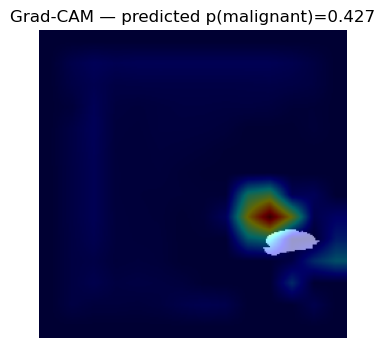

  MAMMOGRAM SCREENING SUPPORT SUMMARY
  For: Demo Patient      Date: 2026-09-28

Your scan shows some features the tool flags as worth a closer look by your doctor.

This is an AI research prototype used ALONGSIDE your care team — it does
not diagnose you, and it is not a substitute for your radiologist's report.

WHAT HAPPENS NEXT:
  Your doctor or radiologist will review your scan directly and will
  explain your results and any next steps. Please keep any scheduled
  follow-up appointments, and reach out to your care team with any
  questions or concerns.

This tool is part of an academic Final Year Project and has not been
clinically validated for real-world diagnostic use.

  CAD DECISION-SUPPORT REPORT (FYP PROTOTYPE)
  Case: Demo Case      Generated: 2026-09-28 03:38

MODEL OUTPUT
  Malignancy probability:  0.427
  Risk band:                Moderate

MODEL RELIABILITY CONTEXT (test-set performance)
  AUC:          0.657
  Sensitivity:  0.075
  Specificity:  0.969
  -> Interpret 

In [27]:
def run_full_pipeline(img_path, true_label=None):
    # Load + preprocess for VGG16
    img_raw = tf.io.read_file(img_path)
    img_raw = tf.image.decode_jpeg(img_raw, channels=3)
    img_raw = tf.image.resize(img_raw, IMG_SIZE)
    img_vgg = preprocess_input(tf.identity(img_raw))
    img_batch = tf.expand_dims(img_vgg, axis=0)

    prob = float(vgg_model.predict(img_batch, verbose=0)[0][0])

    heatmap = make_gradcam_heatmap(img_batch, vgg_model, vgg_base)
    overlay = overlay_gradcam(img_path, heatmap)

    plt.figure(figsize=(4,4))
    plt.imshow(overlay)
    plt.title(f"Grad-CAM — predicted p(malignant)={prob:.3f}")
    plt.axis('off')
    plt.show()

    print(generate_patient_report(prob, patient_ref="Demo Patient"))
    print()
    print(generate_clinical_report(prob, results_stage3, patient_ref="Demo Case"))

    if true_label is not None:
        print(f"\n(True label for reference: {'Malignant' if true_label==1 else 'Benign'})")

# Example — pick the first resolved test image:
demo_row = test_df.iloc[0]
run_full_pipeline(demo_row['img_path'], true_label=demo_row['label'])

### Save the final model

## Stage 4 — Ensembling + Test-Time Augmentation (bridging the benchmark gap)

Following Shen et al. (2019), who improved from a single-model AUC of 0.88 to an ensemble AUC of 0.91, this stage combines the already-trained Stage 2 (regularized CNN) and Stage 3 (VGG16) models by averaging their predicted probabilities — **no retraining required**, since both models are already fitted.

This is also combined with **Test-Time Augmentation (TTA)**: each test image is evaluated multiple times under light augmentation (flips), and predictions are averaged, which reduces prediction variance from any single noisy forward pass.

In [28]:
# ── TTA: average predictions over a few augmented views of each image ──
def predict_with_tta(model, df, preprocess_fn, n_aug=4):
    all_probs = []
    for i in range(n_aug):
        paths = df['img_path'].values
        ds = tf.data.Dataset.from_tensor_slices(paths)

        def _load(p):
            img = tf.io.read_file(p)
            img = tf.image.decode_jpeg(img, channels=3)
            img = tf.image.resize(img, IMG_SIZE)
            if i > 0:   # leave the first pass un-augmented (clean baseline view)
                img = tf.image.random_flip_left_right(img)
                img = tf.image.random_flip_up_down(img)
            img = preprocess_fn(img)
            return img

        ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
        probs = model.predict(ds, verbose=0).flatten()
        all_probs.append(probs)
    return np.mean(all_probs, axis=0)

# Stage 2 uses plain 0-1 scaling; Stage 3 (VGG16) uses preprocess_input
reg_probs_tta = predict_with_tta(reg_model, test_df, lambda img: tf.cast(img, tf.float32) / 255.0)
vgg_probs_tta = predict_with_tta(vgg_model, test_df, preprocess_input)

print("TTA predictions generated for both models.")

TTA predictions generated for both models.


   STAGE 4 - ENSEMBLE (Stage 2 + Stage 3, with TTA)
  AUC (ROC):    0.6610
  Accuracy:     0.5836
  Sensitivity:  0.0612
  Specificity:  0.9794


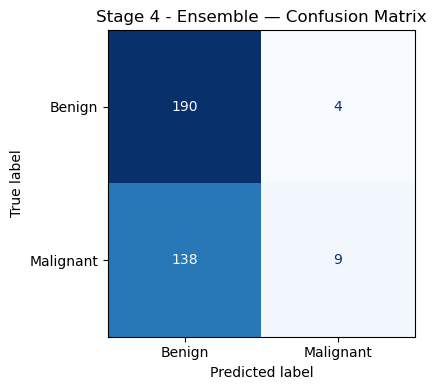

,Model,AUC,Sensitivity,Specificity
0,Stage 1 - Baseline CNN,0.558300,0.993000,0.005000
1,Stage 2 - Regularized CNN,0.556315,0.136054,0.922680
2,Stage 3 - VGG16 Transfer Learning,0.656989,0.074830,0.969072
3,Shen et al. (2019) benchmark,0.895000,0.861000,0.801000
4,Falconi et al. (2020) benchmark,0.844000,NaN,NaN
5,Stage 4 - Ensemble (TTA),0.660951,0.061224,0.979381


In [29]:
# ── Ensemble: average Stage 2 + Stage 3 (TTA) probabilities ────────────
ensemble_probs = (reg_probs_tta + vgg_probs_tta) / 2.0
ensemble_pred  = (ensemble_probs >= 0.5).astype(int)

auc_ens = roc_auc_score(y_true, ensemble_probs)
cm_ens  = confusion_matrix(y_true, ensemble_pred)
tn, fp, fn, tp = cm_ens.ravel()
sens_ens = tp / (tp + fn) if (tp + fn) else 0.0
spec_ens = tn / (tn + fp) if (tn + fp) else 0.0
acc_ens  = (tp + tn) / len(y_true)

print("=" * 50)
print("   STAGE 4 - ENSEMBLE (Stage 2 + Stage 3, with TTA)")
print("=" * 50)
print(f"  AUC (ROC):    {auc_ens:.4f}")
print(f"  Accuracy:     {acc_ens:.4f}")
print(f"  Sensitivity:  {sens_ens:.4f}")
print(f"  Specificity:  {spec_ens:.4f}")
print("=" * 50)

results_stage4 = {"model_name": "Stage 4 - Ensemble (TTA)", "auc": auc_ens,
                   "accuracy": acc_ens, "sensitivity": sens_ens, "specificity": spec_ens}

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(cm_ens, display_labels=['Benign','Malignant']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Stage 4 - Ensemble — Confusion Matrix')
plt.tight_layout(); plt.show()

# Add to the comparison table
comparison_full = pd.concat([comparison, pd.DataFrame([{
    "Model": "Stage 4 - Ensemble (TTA)", "AUC": auc_ens,
    "Sensitivity": sens_ens, "Specificity": spec_ens
}])], ignore_index=True)
comparison_full

### Threshold tuning (Youden's J statistic)

AUC measures ranking ability across all thresholds at once — it does **not** change based on where you set the cutoff. The default 0.5 cutoff produced very poor sensitivity (many missed malignant cases). Here, the optimal threshold is found on the **validation set** (never the test set, to avoid leaking test information into the decision) using Youden's J statistic (`J = TPR - FPR`, maximised), then applied once to the test set.

In [32]:
from sklearn.metrics import roc_curve

# ── Plain (non-TTA) predictions on the VALIDATION set, for threshold selection only ──
def predict_plain(model, df, preprocess_fn):
    paths = df['img_path'].values
    ds = tf.data.Dataset.from_tensor_slices(paths)
    def _load(p):
        img = tf.io.read_file(p)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        img = preprocess_fn(img)
        return img
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return model.predict(ds, verbose=0).flatten()

val_reg_probs = predict_plain(reg_model, val_data, lambda img: tf.cast(img, tf.float32) / 255.0)
val_vgg_probs = predict_plain(vgg_model, val_data, preprocess_input)
val_ensemble_probs = (val_reg_probs + val_vgg_probs) / 2.0
val_y_true = val_data['label'].values

# ── Youden's J statistic: find threshold that maximises (TPR - FPR) ────
fpr, tpr, thresholds = roc_curve(val_y_true, val_ensemble_probs)
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
best_threshold = float(thresholds[best_idx])
print(f"Best threshold (Youden's J, chosen on validation set): {best_threshold:.4f}")
print(f"(Validation TPR at this threshold: {tpr[best_idx]:.4f}, FPR: {fpr[best_idx]:.4f})")

Best threshold (Youden's J, chosen on validation set): 0.3980
(Validation TPR at this threshold: 0.5547, FPR: 0.3217)


   STAGE 4 - ENSEMBLE (threshold-tuned via Youden's J)
  AUC (ROC, unchanged by thresholding): 0.6610
  Accuracy:                             0.6452
  Sensitivity:                          0.3401
  Specificity:                          0.8763
  Threshold used:                       0.3980  (vs. default 0.5)


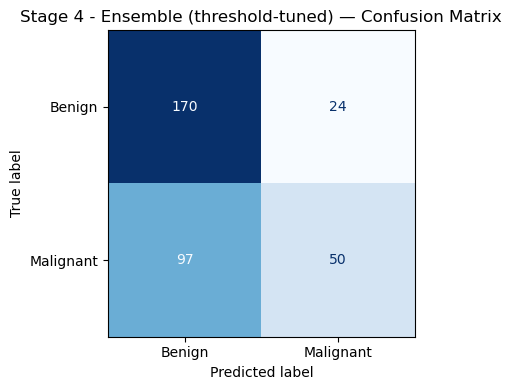

In [33]:
# ── Apply the validation-chosen threshold to the TEST set ensemble probabilities ──
tuned_pred = (ensemble_probs >= best_threshold).astype(int)
cm_tuned = confusion_matrix(y_true, tuned_pred)
tn, fp, fn, tp = cm_tuned.ravel()
sens_tuned = tp / (tp + fn) if (tp + fn) else 0.0
spec_tuned = tn / (tn + fp) if (tn + fp) else 0.0
acc_tuned  = (tp + tn) / len(y_true)
# NOTE: AUC is unchanged by thresholding — it's the same ranking, just re-cut.
auc_tuned  = auc_ens

print("=" * 55)
print("   STAGE 4 - ENSEMBLE (threshold-tuned via Youden's J)")
print("=" * 55)
print(f"  AUC (ROC, unchanged by thresholding): {auc_tuned:.4f}")
print(f"  Accuracy:                             {acc_tuned:.4f}")
print(f"  Sensitivity:                          {sens_tuned:.4f}")
print(f"  Specificity:                          {spec_tuned:.4f}")
print(f"  Threshold used:                       {best_threshold:.4f}  (vs. default 0.5)")
print("=" * 55)

results_stage4_tuned = {"model_name": "Stage 4 - Ensemble (threshold-tuned)", "auc": auc_tuned,
                         "accuracy": acc_tuned, "sensitivity": sens_tuned, "specificity": spec_tuned}

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(cm_tuned, display_labels=['Benign','Malignant']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Stage 4 - Ensemble (threshold-tuned) — Confusion Matrix')
plt.tight_layout(); plt.show()

## Stage 5 — InceptionV3 (following Salama & Aly, 2021)

Salama and Aly (2021) reported their best CBIS-DDSM accuracy — **84.21%** — using InceptionV3, outperforming VGG16 (80.98%) on the same dataset in their own comparison. This stage tries that specific architecture as a genuine model change, using the same two-phase (freeze → fine-tune) approach as Stage 3, so the comparison is fair.

**This requires a full retrain — budget similar time to your Stage 3 VGG16 run.**

In [34]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

# InceptionV3 uses its own preprocessing (scales to [-1, 1], different from VGG16's mean-subtraction)
def load_and_preprocess_inception(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)   # 224x224 is fine — InceptionV3 only needs >=75x75
    img = inception_preprocess(img)
    return img, label

def make_dataset_inception(df, augment_data=False, shuffle=False):
    paths  = df['img_path'].values
    labels = df['label'].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=42)
    ds = ds.map(load_and_preprocess_inception, num_parallel_calls=tf.data.AUTOTUNE)
    if augment_data:
        ds = ds.map(lambda i, l: augment(i, l), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds_inc = make_dataset_inception(train_data, augment_data=True,  shuffle=True)
val_ds_inc   = make_dataset_inception(val_data,   augment_data=False, shuffle=False)
test_ds_inc  = make_dataset_inception(test_df,    augment_data=False, shuffle=False)

def build_inceptionv3_model():
    base = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base.trainable = False   # frozen for Phase A

    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)   # lower than VGG16's 0.3 -> deliberately less aggressive than Stage 3's 0.5
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs)
    return model, base

inception_model, inception_base = build_inceptionv3_model()
inception_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                         loss='binary_crossentropy',
                         metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
inception_model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ inception_v3 (Functional)            │ (None, 5, 5, 2048)          │      21,802,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,065,185 (84.17 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [35]:
# ── Phase A: train the classification head only (base frozen) ───────────
print("Phase A: training classifier head (InceptionV3 base frozen)...\n")
history_inc_a = inception_model.fit(
    train_ds_inc, validation_data=val_ds_inc,
    epochs=10, class_weight=class_weights,
    callbacks=[EarlyStopping(monitor='val_auc', mode='max', patience=4, restore_best_weights=True)],
    verbose=1
)

# ── Phase B: unfreeze the last two inception blocks and fine-tune at a low LR ──
inception_base.trainable = True
for layer in inception_base.layers[:-30]:   # InceptionV3 has many small layers per block; -30 ~= last 2 blocks
    layer.trainable = False

inception_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                         loss='binary_crossentropy',
                         metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

print("\nPhase B: fine-tuning top InceptionV3 blocks...\n")
history_inc_b = inception_model.fit(
    train_ds_inc, validation_data=val_ds_inc,
    epochs=15, class_weight=class_weights,
    callbacks=[EarlyStopping(monitor='val_auc', mode='max', patience=5, restore_best_weights=True),
               ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=2, min_lr=1e-7)],
    verbose=1
)
print("\nStage 5 training complete!")

Phase A: training classifier head (InceptionV3 base frozen)...

Epoch 1/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.5345 - auc: 0.5383 - loss: 0.7976 - val_accuracy: 0.6049 - val_auc: 0.6761 - val_loss: 0.6788
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.5716 - auc: 0.6118 - loss: 0.6963 - val_accuracy: 0.6049 - val_auc: 0.6633 - val_loss: 0.6858
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.6056 - auc: 0.6670 - loss: 0.6653 - val_accuracy: 0.6296 - val_auc: 0.6758 - val_loss: 0.6586
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.6179 - auc: 0.6846 - loss: 0.6523 - val_accuracy: 0.6132 - val_auc: 0.6749 - val_loss: 0.6782
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.6128 - auc: 0.6738 - loss: 0.6665 - val_accuracy: 0.6420 - val_auc: 0.7012 - val_loss: 0.6476
Epoch 6/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.6220 - auc: 0.6898 - loss: 0.6547 - val_accuracy: 0.6461 - val_auc: 0.7030 - val_l

       Stage 5 - InceptionV3 Transfer Learning — TEST SET RESULTS
  AUC (ROC):    0.7133
  Accuracy:     0.6686
  Sensitivity:  0.6122  (malignant recall)
  Specificity:  0.7113


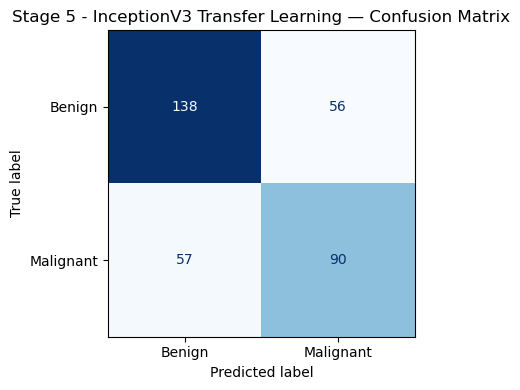

In [36]:
results_stage5 = evaluate_model(inception_model, test_ds_inc, y_true, label="Stage 5 - InceptionV3 Transfer Learning")

### Stage 6 — 3-Model Ensemble (VGG16 + Regularized CNN + InceptionV3), accuracy-optimized threshold

Same ensembling principle as Stage 4, now with three models instead of two, plus TTA. This time the validation-set threshold search maximises **accuracy** directly (rather than Youden's J, which balances sensitivity/specificity) — matching the goal of this stage.

In [37]:
# ── TTA predictions for InceptionV3 (reuse predict_with_tta, different preprocessing) ──
inception_probs_tta = predict_with_tta(inception_model, test_df, inception_preprocess)

# ── 3-way ensemble (average of all three models' TTA probabilities) ────
ensemble3_probs = (reg_probs_tta + vgg_probs_tta + inception_probs_tta) / 3.0

# ── Validation-set predictions for threshold selection (plain, no TTA) ──
val_inception_probs = predict_plain(inception_model, val_data, inception_preprocess)
val_ensemble3_probs = (val_reg_probs + val_vgg_probs + val_inception_probs) / 3.0

# ── Threshold search that maximises ACCURACY on validation set ──────────
candidate_thresholds = np.linspace(0.05, 0.95, 181)
val_accuracies = [
    ((val_ensemble3_probs >= t).astype(int) == val_y_true).mean()
    for t in candidate_thresholds
]
best_acc_threshold = float(candidate_thresholds[np.argmax(val_accuracies)])
print(f"Best threshold for ACCURACY (chosen on validation set): {best_acc_threshold:.3f}")
print(f"Validation accuracy at this threshold: {max(val_accuracies):.4f}")

Best threshold for ACCURACY (chosen on validation set): 0.405
Validation accuracy at this threshold: 0.6626


   STAGE 6 - 3-MODEL ENSEMBLE (accuracy-optimized threshold)
  AUC (ROC):     0.7404
  Accuracy:      0.7038
  Sensitivity:   0.6259
  Specificity:   0.7629
  Threshold:     0.405  (accuracy-optimized, vs. default 0.5)


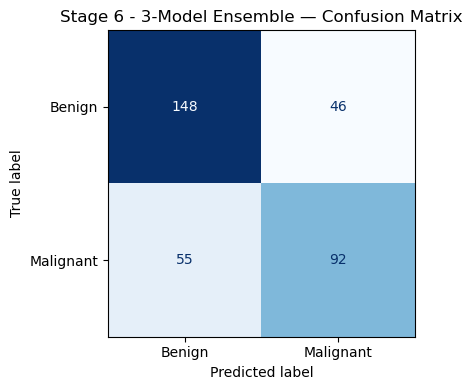

In [38]:
# ── Apply to the TEST set ────────────────────────────────────────────────
final_pred = (ensemble3_probs >= best_acc_threshold).astype(int)
cm_final = confusion_matrix(y_true, final_pred)
tn, fp, fn, tp = cm_final.ravel()
sens_final = tp / (tp + fn) if (tp + fn) else 0.0
spec_final = tn / (tn + fp) if (tn + fp) else 0.0
acc_final  = (tp + tn) / len(y_true)
auc_final  = roc_auc_score(y_true, ensemble3_probs)

print("=" * 55)
print("   STAGE 6 - 3-MODEL ENSEMBLE (accuracy-optimized threshold)")
print("=" * 55)
print(f"  AUC (ROC):     {auc_final:.4f}")
print(f"  Accuracy:      {acc_final:.4f}")
print(f"  Sensitivity:   {sens_final:.4f}")
print(f"  Specificity:   {spec_final:.4f}")
print(f"  Threshold:     {best_acc_threshold:.3f}  (accuracy-optimized, vs. default 0.5)")
print("=" * 55)

results_stage6 = {"model_name": "Stage 6 - 3-Model Ensemble (accuracy-optimized)", "auc": auc_final,
                   "accuracy": acc_final, "sensitivity": sens_final, "specificity": spec_final}

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(cm_final, display_labels=['Benign','Malignant']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Stage 6 - 3-Model Ensemble — Confusion Matrix')
plt.tight_layout(); plt.show()

In [39]:
vgg_model.save('breast_cancer_vgg16_final.keras')
print("Saved: breast_cancer_vgg16_final.keras")

Saved: breast_cancer_vgg16_final.keras
